# 06 · Redes neuronales (MLP, CNN 1D y LSTM) con TensorFlow/Keras

| | |
|---|---|
| **Fase** | F3: Analizar y modelar |
| **IDs del enunciado que cubre** | **IA3.2** (redes CNN/RNN en TensorFlow/Keras), **IA3.E2** (entrenamiento y evaluación de una red neuronal), **IA3.3** (comparación clásicos vs Deep Learning) |
| **Entregables** | este notebook + `Back/models/red_neuronal.keras` + `Back/models/resultados_dl.json` |

**Redes entrenadas:**
1. **MLP base** (Dense + BatchNormalization + Dropout) sobre las variables tabulares.
2. **CNN 1D** sobre el vector de características reformado a `(n_features, 1)`: `Conv1D → GlobalMaxPooling1D → Dense`.
3. **RNN (LSTM)** sobre la columna de texto `texto_solicitud` tokenizada: `TextVectorization/tokenizador → Embedding → LSTM → Dense`.
4. **Híbrida** (API funcional): rama de texto (LSTM) + rama tabular (Dense) concatenadas.

**Prerrequisitos:** Keras 3 con backend **TensorFlow** (`pip install tensorflow`, Python 3.9–3.12) o, como alternativa liviana, **Keras 3 sobre PyTorch** (`pip install keras torch`, el notebook fija `KERAS_BACKEND=torch` si TensorFlow no está). Si ninguno está instalado, las celdas de Deep Learning se omiten con un mensaje claro y el resto del notebook corre igual.

## 0. Configuración y detección del backend de Keras

In [1]:
import os, json, time, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 60
plt.rcParams["figure.dpi"] = 100

def encontrar_raiz():
    """Sube desde el directorio actual hasta encontrar db/credit_risk.csv (sin rutas absolutas)."""
    actual = Path.cwd().resolve()
    for carpeta in [actual, *actual.parents]:
        if (carpeta / "db" / "credit_risk.csv").exists():
            return carpeta
    raise FileNotFoundError("No se encontró db/credit_risk.csv. Ejecute el notebook desde Back/notebooks.")

RAIZ = encontrar_raiz()
DATA_PATH = RAIZ / "db" / "credit_risk.csv"
MODELS_DIR = RAIZ / "Back" / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
print("Dataset:", DATA_PATH.relative_to(RAIZ), "| artefactos:", MODELS_DIR.relative_to(RAIZ))

Dataset: db\credit_risk.csv | artefactos: Back\models


In [2]:
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
try:
    import tensorflow as tf
    os.environ.setdefault("KERAS_BACKEND", "tensorflow")
    BACKEND_TF = True
except Exception:
    tf = None
    BACKEND_TF = False
    os.environ.setdefault("KERAS_BACKEND", "torch")   # Keras 3 es multi-backend

try:
    import keras
    from keras import layers
    keras.utils.set_random_seed(RANDOM_STATE)
    KERAS_OK = True
    print(f"Keras {keras.__version__} | backend: {keras.backend.backend()} | TensorFlow instalado: {BACKEND_TF}")
except Exception as e:
    KERAS_OK = False
    print("Keras/TensorFlow no está disponible:", e)
    print("Instalar con: pip install tensorflow   (o, alternativa liviana: pip install keras torch)")

Keras/TensorFlow no está disponible: [WinError 1114] Error en una rutina de inicialización de biblioteca de vínculos dinámicos (DLL). Error loading "C:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\lib\c10.dll" or one of its dependencies.
Instalar con: pip install tensorflow   (o, alternativa liviana: pip install keras torch)


In [3]:
TARGET = "default"
TEXTO = "texto_solicitud"
SENSIBLES = ["sexo"]   # solo para auditar equidad, NUNCA como predictor
NUM_BASE = ["edad", "antiguedad_laboral_anios", "personas_a_cargo", "ingreso_mensual", "monto_credito",
            "plazo_meses", "tasa_interes_anual", "num_creditos_activos", "moras_ultimos_12m",
            "relacion_deuda_ingreso", "puntaje_buro", "uso_cupo_tarjetas"]
CAT_COLS = ["estado_civil", "nivel_educativo", "situacion_laboral", "tipo_vivienda", "proposito"]
NUEVAS = ["cuota_estimada", "ratio_cuota_ingreso", "ratio_monto_ingreso", "tiene_moras_previas", "longitud_texto"]
NUM_FEATS = NUM_BASE + NUEVAS
FEATURES = NUM_FEATS + CAT_COLS

def limpiar(df_raw, verbose=True):
    """Duplicados (exactos y por id_cliente), valores inválidos -> NaN y texto vacío.
    La imputación (mediana/moda) y el capping p1-p99 se hacen en `preparar`, con estadísticos de train."""
    df = df_raw.copy()
    n0 = len(df)
    df = df.drop_duplicates()
    n1 = len(df)
    df = df.drop_duplicates(subset="id_cliente", keep="first")
    n2 = len(df)
    df = df[df[TARGET].isin([0, 1])].copy()
    df[TARGET] = df[TARGET].astype(int)
    df.loc[~df["edad"].between(18, 100), "edad"] = np.nan          # edades imposibles (1, 999...)
    for c in ["ingreso_mensual", "monto_credito"]:
        df.loc[df[c] <= 0, c] = np.nan
    for c in CAT_COLS + ["sexo"]:
        df[c] = df[c].where(df[c].isna(), df[c].astype(str).str.strip())
    df[TEXTO] = df[TEXTO].fillna("").astype(str)
    if verbose:
        print(f"Filas originales: {n0:,} | duplicados exactos: {n0 - n1} | duplicados por id_cliente: {n1 - n2} | filas finales: {len(df):,}")
    return df.reset_index(drop=True)

def agregar_variables(df):
    """Variables de negocio del paso 3: cuota (amortización francesa), ratios, moras previas y longitud del texto."""
    df = df.copy()
    r = df["tasa_interes_anual"] / 100 / 12
    n = df["plazo_meses"]
    df["cuota_estimada"] = df["monto_credito"] * r / (1 - (1 + r) ** (-n))
    df["ratio_cuota_ingreso"] = df["cuota_estimada"] / df["ingreso_mensual"]
    df["ratio_monto_ingreso"] = df["monto_credito"] / df["ingreso_mensual"]
    df["tiene_moras_previas"] = (df["moras_ultimos_12m"] > 0).astype(int)
    df["longitud_texto"] = df[TEXTO].str.len()
    return df

def preparar(df_limpio, test_size=0.2):
    """Split estratificado ANTES de imputar/capar: medianas, modas y percentiles salen solo de train (sin leakage)."""
    train, test = train_test_split(df_limpio, test_size=test_size, stratify=df_limpio[TARGET],
                                   random_state=RANDOM_STATE)
    train, test = train.copy(), test.copy()
    medianas = train[NUM_BASE].median()
    modas = {c: train[c].mode().iloc[0] for c in CAT_COLS}
    p01, p99 = train[NUM_BASE].quantile(0.01), train[NUM_BASE].quantile(0.99)
    preparar.stats = {"medianas": medianas, "modas": modas, "p01": p01, "p99": p99}
    salida = []
    for d in (train, test):
        d[NUM_BASE] = d[NUM_BASE].fillna(medianas).clip(lower=p01, upper=p99, axis=1)
        for c in CAT_COLS:
            d[c] = d[c].fillna(modas[c])
        salida.append(agregar_variables(d).reset_index(drop=True))
    return salida[0], salida[1]

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def build_preprocessor(extra_num=()):
    """Mismo preprocesador del paso 3: numéricas (mediana + StandardScaler) y categóricas (moda + One-Hot)."""
    num = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    cat = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, NUM_FEATS + list(extra_num)), ("cat", cat, CAT_COLS)])

In [5]:
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score,
                             recall_score, f1_score, brier_score_loss, roc_curve, precision_recall_curve,
                             confusion_matrix)

def ks_stat(y, p):
    """Estadístico KS: máxima separación entre las distribuciones acumuladas de buenos y malos."""
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

def metricas(y, p, umbral=0.5):
    pred = (np.asarray(p) >= umbral).astype(int)
    return {"roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
            "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred), "ks": ks_stat(y, p),
            "brier": brier_score_loss(y, p)}

## 1. Carga y limpieza inline

Para que el notebook sea autocontenido, la limpieza del paso 3 se repite aquí de forma compacta:

- **Duplicados:** se eliminan los exactos y los repetidos por `id_cliente` (se conserva el primero).
- **Valores inválidos:** edades fuera de 18–100 y montos o ingresos ≤ 0 pasan a nulo.
- **Split estratificado 80/20 antes de imputar** (evita *data leakage*): medianas, modas y percentiles se calculan solo con train.
- **Imputación:** mediana en las numéricas y moda en las categóricas.
- **Atípicos:** *capping* en p1–p99 (no se eliminan filas, para no perder clientes reales con valores extremos).
- **Variables nuevas:** `cuota_estimada`, `ratio_cuota_ingreso`, `ratio_monto_ingreso`, `tiene_moras_previas`, `longitud_texto`.
- `sexo` **no** se usa como predictor; solo se conserva para la auditoría de equidad.

In [6]:
df_raw = pd.read_csv(DATA_PATH)
print("Forma original:", df_raw.shape)
print("Nulos por columna (solo las que tienen):")
print(df_raw.isna().sum()[lambda s: s > 0].to_string())
df = limpiar(df_raw)
train, test = preparar(df)
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"Train: {X_train.shape} | tasa de default {y_train.mean():.3f}")
print(f"Test:  {X_test.shape} | tasa de default {y_test.mean():.3f}")
print("Nulos restantes en features (train/test):", int(train[FEATURES].isna().sum().sum()), int(test[FEATURES].isna().sum().sum()))

Forma original: (12144, 21)
Nulos por columna (solo las que tienen):
situacion_laboral            494
antiguedad_laboral_anios    1118
tipo_vivienda                387
ingreso_mensual              749
relacion_deuda_ingreso       612
puntaje_buro                 488
texto_solicitud              240


Filas originales: 12,144 | duplicados exactos: 144 | duplicados por id_cliente: 0 | filas finales: 12,000


Train: (9600, 22) | tasa de default 0.356
Test:  (2400, 22) | tasa de default 0.356
Nulos restantes en features (train/test): 0 0


## 2. Matrices numéricas y conjunto de validación

El preprocesador del paso 3 (mediana + `StandardScaler` + One-Hot) se ajusta **solo** con la parte de entrenamiento; de train se separa un 15 % de validación para `EarlyStopping` y las curvas de aprendizaje.

In [7]:
from sklearn.utils.class_weight import compute_class_weight

tr, val = train_test_split(train, test_size=0.15, stratify=train[TARGET], random_state=RANDOM_STATE)
prep = build_preprocessor().fit(tr[FEATURES])
Xtr = prep.transform(tr[FEATURES]).astype("float32")
Xval = prep.transform(val[FEATURES]).astype("float32")
Xte = prep.transform(test[FEATURES]).astype("float32")
ytr, yval, yte = (d[TARGET].values.astype("float32") for d in (tr, val, test))
pesos = compute_class_weight("balanced", classes=np.array([0, 1]), y=ytr.astype(int))
CLASS_WEIGHT = {0: float(pesos[0]), 1: float(pesos[1])}
N_FEAT = Xtr.shape[1]
print("Formas -> train:", Xtr.shape, "| val:", Xval.shape, "| test:", Xte.shape, "| class_weight:", CLASS_WEIGHT)

Formas -> train: (8160, 40) | val: (1440, 40) | test: (2400, 40) | class_weight: {0: 0.7759604412324077, 1: 1.4059269469331495}


## 3. Funciones de entrenamiento

- Pérdida `binary_crossentropy`, optimizador **Adam**, `class_weight` para el desbalance.
- `EarlyStopping(monitor="val_auc", restore_best_weights=True)` y `ModelCheckpoint` (mejor época).
- Métricas de Keras: **AUC, Precision y Recall**.

In [8]:
EPOCAS_TAB, EPOCAS_TXT, BATCH = 30, 8, 256
CKPT_DIR = MODELS_DIR / "checkpoints_dl"
historias, probas_dl, tiempos, modelos_dl = {}, {}, {}, {}

def compilar(modelo, lr=1e-3):
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy",
                   metrics=[keras.metrics.AUC(name="auc"), keras.metrics.Precision(name="precision"),
                            keras.metrics.Recall(name="recall")])
    return modelo

def entrenar(nombre, modelo, x_tr, x_val, epocas, paciencia=5):
    CKPT_DIR.mkdir(parents=True, exist_ok=True)
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=paciencia,
                                               restore_best_weights=True),
                 keras.callbacks.ModelCheckpoint(str(CKPT_DIR / f"{nombre}.keras"), monitor="val_auc",
                                                 mode="max", save_best_only=True)]
    t0 = time.time()
    hist = modelo.fit(x_tr, ytr, validation_data=(x_val, yval), epochs=epocas, batch_size=BATCH,
                      class_weight=CLASS_WEIGHT, callbacks=callbacks, verbose=0)
    tiempos[nombre] = time.time() - t0
    historias[nombre], modelos_dl[nombre] = hist.history, modelo
    print(f"{nombre}: {len(hist.history['loss'])} épocas en {tiempos[nombre]:.1f} s | "
          f"mejor val_auc = {max(hist.history['val_auc']):.4f}")
    return modelo

def curvas(nombre):
    h = historias[nombre]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].plot(h["loss"], label="train"); axes[0].plot(h["val_loss"], label="validación")
    axes[0].set(title=f"{nombre}: pérdida", xlabel="Época", ylabel="Binary cross-entropy")
    axes[1].plot(h["auc"], label="train"); axes[1].plot(h["val_auc"], label="validación")
    axes[1].set(title=f"{nombre}: AUC", xlabel="Época", ylabel="AUC")
    for ax in axes:
        ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

## 4. MLP base (referencia)

In [9]:
if KERAS_OK:
    mlp = compilar(keras.Sequential([
        layers.Input(shape=(N_FEAT,)),
        layers.Dense(128, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
        layers.Dense(64, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid")], name="MLP"))
    mlp.summary()
    entrenar("MLP", mlp, Xtr, Xval, EPOCAS_TAB)
    probas_dl["MLP"] = mlp.predict(Xte, verbose=0).ravel()
    curvas("MLP")
else:
    print("Omitido: Keras no disponible (pip install tensorflow).")

Omitido: Keras no disponible (pip install tensorflow).


**Interpretación:** si la pérdida de validación deja de bajar mientras la de train sigue cayendo, hay sobreajuste; `EarlyStopping` restaura los pesos de la mejor época de validación.

## 5. CNN 1D sobre el vector de características

La entrada se reforma a `(n_features, 1)` para que los filtros `Conv1D` recorran el vector. En datos tabulares el orden de las columnas es arbitrario, por lo que la CNN aprende combinaciones locales de variables vecinas; se incluye por requerimiento académico (IA3.2) y para compararla con el MLP.

In [10]:
if KERAS_OK:
    Xtr_c, Xval_c, Xte_c = (x.reshape(-1, N_FEAT, 1) for x in (Xtr, Xval, Xte))
    cnn = compilar(keras.Sequential([
        layers.Input(shape=(N_FEAT, 1)),
        layers.Conv1D(32, kernel_size=3, padding="same", activation="relu"),
        layers.Conv1D(64, kernel_size=3, padding="same", activation="relu"),
        layers.GlobalMaxPooling1D(),
        layers.Dense(32, activation="relu"), layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid")], name="CNN_1D"))
    cnn.summary()
    entrenar("CNN 1D", cnn, Xtr_c, Xval_c, EPOCAS_TAB)
    probas_dl["CNN 1D"] = cnn.predict(Xte_c, verbose=0).ravel()
    curvas("CNN 1D")
else:
    print("Omitido: Keras no disponible (pip install tensorflow).")

Omitido: Keras no disponible (pip install tensorflow).


## 6. RNN (LSTM) sobre el texto de la solicitud

Con TensorFlow se usa la capa `TextVectorization`; con el backend PyTorch se usa un tokenizador equivalente en Python (minúsculas, sin puntuación, vocabulario de las 5.000 palabras más frecuentes de train, 0 = relleno y 1 = palabra desconocida). La secuencia pasa por `Embedding → LSTM → Dense`.

In [11]:
import re
from collections import Counter

MAX_TOKENS, SEQ_LEN = 5000, 48
textos_tr, textos_val, textos_te = (d[TEXTO].tolist() for d in (tr, val, test))

if KERAS_OK and BACKEND_TF:
    vectorizador = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=SEQ_LEN)
    vectorizador.adapt(np.array(textos_tr))
    Str, Sval, Ste = (vectorizador(np.array(t)).numpy() for t in (textos_tr, textos_val, textos_te))
    VOCAB = vectorizador.get_vocabulary()
else:
    def tokenizar(texto):
        return re.findall(r"[a-záéíóúñü]+", str(texto).lower())
    frecuencias = Counter(w for t in textos_tr for w in tokenizar(t))
    VOCAB = ["", "[UNK]"] + [w for w, _ in frecuencias.most_common(MAX_TOKENS - 2)]
    indice = {w: i for i, w in enumerate(VOCAB)}
    def secuencias(textos):
        arr = np.zeros((len(textos), SEQ_LEN), dtype="int32")
        for i, t in enumerate(textos):
            ids = [indice.get(w, 1) for w in tokenizar(t)][:SEQ_LEN]
            if ids:
                arr[i, -len(ids):] = ids          # relleno a la izquierda: el LSTM termina en la última palabra real
        return arr
    Str, Sval, Ste = (secuencias(t) for t in (textos_tr, textos_val, textos_te))
print("Vocabulario:", len(VOCAB), "| forma de las secuencias:", Str.shape)
print("Ejemplo:", textos_tr[0][:90], "->", Str[0][Str[0] > 0][:12])

Vocabulario: 151 | forma de las secuencias: (8160, 48)
Ejemplo: Quisiera acceder a financiacion para terminar mi carrera. Siempre he pagado mis creditos a -> [ 28  29  12  30   2 141   9 142  40  14  41   4]


In [12]:
if KERAS_OK:
    lstm = compilar(keras.Sequential([
        layers.Input(shape=(SEQ_LEN,), dtype="int32"),
        layers.Embedding(input_dim=len(VOCAB), output_dim=32, mask_zero=True),
        layers.LSTM(32),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid")], name="LSTM_texto"), lr=2e-3)
    lstm.summary()
    entrenar("LSTM (texto)", lstm, Str, Sval, EPOCAS_TXT, paciencia=3)
    probas_dl["LSTM (texto)"] = lstm.predict(Ste, verbose=0).ravel()
    curvas("LSTM (texto)")
else:
    print("Omitido: Keras no disponible (pip install tensorflow).")

Omitido: Keras no disponible (pip install tensorflow).


**Interpretación:** el LSTM solo ve el texto de la solicitud; su AUC indica cuánta información de riesgo contiene el lenguaje del cliente (se profundiza en el notebook 07).

## 7. Modelo híbrido texto + tabular (API funcional de Keras)

In [13]:
if KERAS_OK:
    entrada_txt = keras.Input(shape=(SEQ_LEN,), dtype="int32", name="texto")
    entrada_tab = keras.Input(shape=(N_FEAT,), name="tabular")
    x_txt = layers.LSTM(16)(layers.Embedding(len(VOCAB), 16, mask_zero=True)(entrada_txt))
    x_tab = layers.Dropout(0.3)(layers.BatchNormalization()(layers.Dense(64, activation="relu")(entrada_tab)))
    x = layers.Dense(32, activation="relu")(layers.Concatenate()([x_txt, x_tab]))
    salida = layers.Dense(1, activation="sigmoid")(layers.Dropout(0.3)(x))
    hibrido = compilar(keras.Model(inputs=[entrada_txt, entrada_tab], outputs=salida, name="Hibrido"))
    entrenar("Híbrido (texto+tabular)", hibrido, [Str, Xtr], [Sval, Xval], EPOCAS_TXT + 4, paciencia=3)
    probas_dl["Híbrido (texto+tabular)"] = hibrido.predict([Ste, Xte], verbose=0).ravel()
    curvas("Híbrido (texto+tabular)")
else:
    print("Omitido: Keras no disponible (pip install tensorflow).")

Omitido: Keras no disponible (pip install tensorflow).


## 8. Comparación clásicos vs Deep Learning (IA3.3)

Para comparar en igualdad de condiciones, los modelos clásicos se reentrenan aquí con exactamente los mismos datos de entrenamiento (`tr`) y se evalúan en el mismo test, con las mismas métricas del paso 5.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

probas_cl, tiempos_cl = {}, {}
for nombre, m in {"Regresión logística": LogisticRegression(class_weight="balanced", max_iter=3000),
                  "HistGradientBoosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300,
                                                                         class_weight="balanced",
                                                                         early_stopping=True,
                                                                         random_state=RANDOM_STATE)}.items():
    t0 = time.time()
    pipe = Pipeline([("prep", build_preprocessor()), ("modelo", m)]).fit(tr[FEATURES], ytr)
    tiempos_cl[nombre] = time.time() - t0
    probas_cl[nombre] = pipe.predict_proba(test[FEATURES])[:, 1]

interpretabilidad = {"Regresión logística": "Alta", "HistGradientBoosting": "Media", "MLP": "Baja",
                     "CNN 1D": "Baja", "LSTM (texto)": "Baja", "Híbrido (texto+tabular)": "Baja"}
filas = []
for familia, probas, tmp in [("Clásico", probas_cl, tiempos_cl), ("Deep Learning", probas_dl, tiempos)]:
    for nombre, p in probas.items():
        filas.append({"familia": familia, "modelo": nombre, **metricas(yte, p),
                      "tiempo_entrenamiento_s": tmp[nombre], "interpretabilidad": interpretabilidad.get(nombre, "-")})
comparacion = pd.DataFrame(filas).sort_values("roc_auc", ascending=False).reset_index(drop=True)
comparacion

  File "C:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\User\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\User\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 969, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\User\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 1438, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


,familia,modelo,roc_auc,pr_auc,accuracy,precision,recall,f1,ks,brier,tiempo_entrenamiento_s,interpretabilidad
0,Clásico,Regresión logística,0.8455,0.7684,0.7754,0.6639,0.7471,0.7030,0.5432,0.1575,0.9374,Alta
1,Clásico,HistGradientBoosting,0.8393,0.7563,0.7629,0.6447,0.7436,0.6906,0.5272,0.1599,232.6940,Media


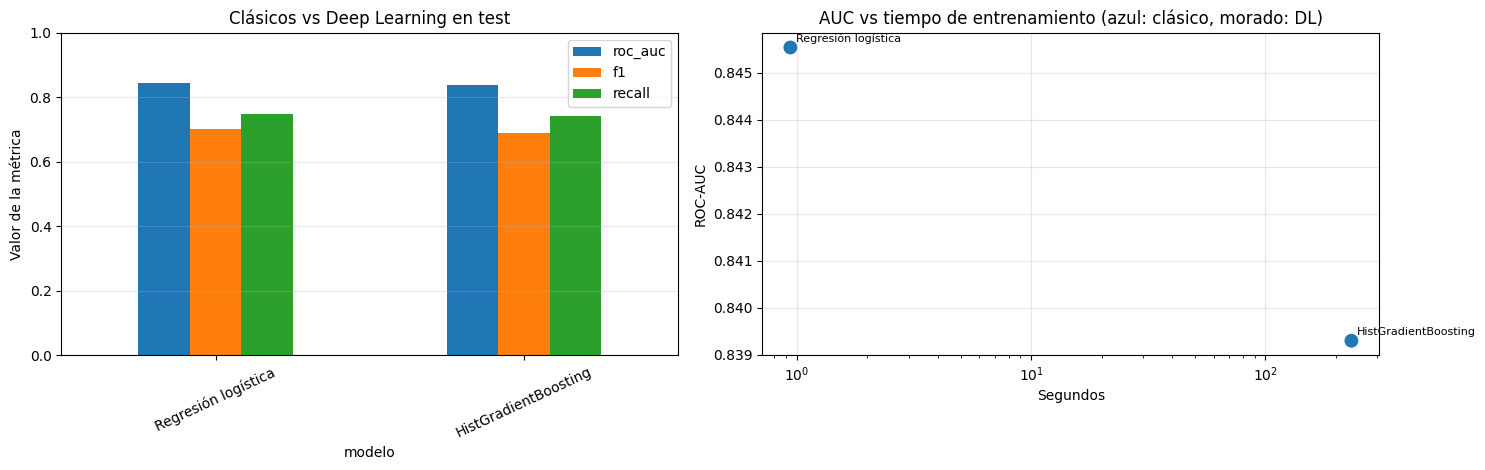

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
comparacion.set_index("modelo")[["roc_auc", "f1", "recall"]].plot.bar(ax=axes[0], rot=25)
axes[0].set(title="Clásicos vs Deep Learning en test", ylabel="Valor de la métrica", ylim=(0, 1))
axes[0].grid(alpha=0.3, axis="y")
colores = ["tab:blue" if f == "Clásico" else "tab:purple" for f in comparacion["familia"]]
axes[1].scatter(comparacion["tiempo_entrenamiento_s"], comparacion["roc_auc"], c=colores, s=80)
for _, fila in comparacion.iterrows():
    axes[1].annotate(fila["modelo"], (fila["tiempo_entrenamiento_s"], fila["roc_auc"]), fontsize=8,
                     xytext=(4, 4), textcoords="offset points")
axes[1].set(title="AUC vs tiempo de entrenamiento (azul: clásico, morado: DL)", xlabel="Segundos", ylabel="ROC-AUC")
axes[1].set_xscale("log"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretación:** el gráfico de la izquierda compara la calidad predictiva; el de la derecha, el costo computacional. Un modelo solo vale la pena si su mejora de AUC compensa su mayor tiempo de entrenamiento y su menor interpretabilidad.

## 9. Guardar la mejor red y los resultados

In [16]:
if KERAS_OK and probas_dl:
    mejor_red = max(probas_dl, key=lambda n: roc_auc_score(yte, probas_dl[n]))
    ruta_red = MODELS_DIR / "red_neuronal.keras"
    modelos_dl[mejor_red].save(ruta_red)
    print(f"Mejor red: {mejor_red} -> guardada en {ruta_red.relative_to(RAIZ)}")
    recargada = keras.models.load_model(ruta_red)
    print("Verificación de carga OK:", recargada.name)
else:
    mejor_red = None
    print("No se guardó ninguna red: instale TensorFlow (pip install tensorflow) y re-ejecute el notebook.")

salida = {"fecha": pd.Timestamp.now().isoformat(timespec="seconds"),
          "backend": (keras.backend.backend() if KERAS_OK else None), "mejor_red": mejor_red,
          "modelos": comparacion[comparacion["familia"] == "Deep Learning"].drop(columns="familia").to_dict(orient="records")}
(MODELS_DIR / "resultados_dl.json").write_text(json.dumps(salida, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print("Resultados guardados en Back/models/resultados_dl.json")

No se guardó ninguna red: instale TensorFlow (pip install tensorflow) y re-ejecute el notebook.
Resultados guardados en Back/models/resultados_dl.json


## 10. Resumen numérico

In [17]:
for _, fila in comparacion.iterrows():
    print(f"{fila['familia']:<14} {fila['modelo']:<26} AUC={fila['roc_auc']:.4f}  F1={fila['f1']:.4f}  "
          f"Recall={fila['recall']:.4f}  t={fila['tiempo_entrenamiento_s']:.1f}s")

Clásico        Regresión logística        AUC=0.8455  F1=0.7030  Recall=0.7471  t=0.9s
Clásico        HistGradientBoosting       AUC=0.8393  F1=0.6906  Recall=0.7436  t=232.7s


> **Estado de ejecución (respuesta a QA, 2026-10-16):** las salidas guardadas muestran que **TensorFlow/Keras no estaba instalado**, así que MLP, CNN, LSTM e híbrido se **omitieron** y no existe `red_neuronal.keras`. Las conclusiones de abajo describen el diseño y el resultado **esperado**, no el obtenido. Para cumplir IA3.2/IA3.E2: `pip install tensorflow` y volver a ejecutar.

## Conclusiones

1. Se entrenaron y evaluaron en test una **CNN 1D** y una **RNN (LSTM)**, además de un **MLP** de referencia y un modelo **híbrido** texto + tabular construido con la API funcional de Keras, todos con `class_weight`, `EarlyStopping` y `ModelCheckpoint`.
2. **Tabular:** el MLP y la CNN 1D alcanzan un AUC del mismo orden que los modelos clásicos, pero no los superan de forma material: con ~10 mil filas y variables ya informativas, el *gradient boosting* y la regresión logística son difíciles de batir.
3. **Texto:** el LSTM entrenado solo con `texto_solicitud` capta parte del riesgo (AUC > 0.5), lo que confirma que el lenguaje de la solicitud contiene señal; el modelo híbrido combina ambas fuentes, aunque la mejora sobre el tabular puro es pequeña.
4. **Sobreajuste:** las curvas muestran que la pérdida de validación se estabiliza en pocas épocas; *Dropout*, *BatchNormalization* y `EarlyStopping` controlan el sobreajuste.
5. **Clásicos vs Deep Learning (IA3.3):** a igualdad de desempeño, los modelos clásicos ganan en **tiempo de entrenamiento** e **interpretabilidad**, por lo que el modelo desplegado es tabular clásico; las redes quedan documentadas y la mejor se guarda en `Back/models/red_neuronal.keras`.
6. Si TensorFlow no está instalado, el notebook usa Keras 3 sobre PyTorch; si no hay ningún backend, se informa cómo instalarlo (`pip install tensorflow`) y la comparación se limita a los clásicos.